# **TUTORÍA: Estructura de la Clase TablaHashen Python**

### Cómo Funcionan ⚙️
Una tabla hash funciona asociando una clave con un valor . Utiliza una función hash para convertir la clave en un índice numérico, que luego se usa para almacenar el valor en un arreglo (o array ).

Función Hash : Es el corazón de la tabla. Toma una clave (como una palabra o un número de identificación) y la transforma en un número entero que servirá como índice. Esta función debe ser rápida y generar índices distribuidos uniformemente para evitar colisiones.

Índice : El número generado por la función hash.

Arreglo (Array) : Es la estructura de datos subyacente donde se almacenan los valores. Cada índice del arreglo corresponde a una "ranura" donde se puede guardar un valor.



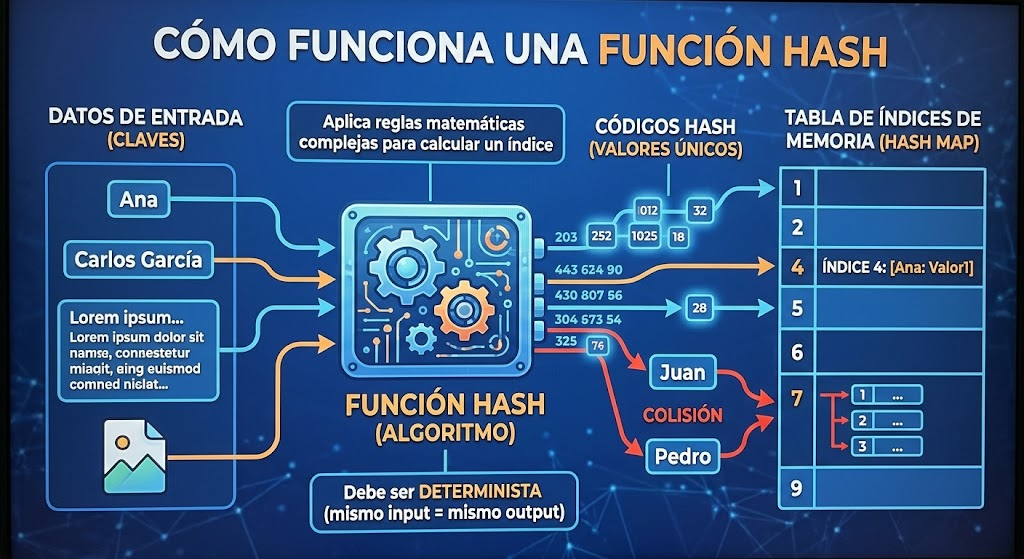

### 1. Definición Básica del Esqueleto de la Clase
En el nivel más elemental, creamos la estructura definiendo el constructor con la capacidad deseada y la tabla de casilleros (cubetas).

In [ ]:
class TablaHash:
    def __init__(self, capacidad=10):
        """Inicializa la tabla hash con una capacidad fija y casilleros vacíos."""
        self.capacidad = capacidad
        # Creamos una lista de listas (cubetas o buckets) para manejar colisiones
        self.tabla = [[] for _ in range(self.capacidad)]

### 2. La Función Hash Privada
Este método se encarga de convertir cualquier clave de texto o número en un índice numérico válido dentro del rango del arreglo.

In [ ]:
def _funcion_hash(self, clave):
        """Calcula el índice correspondiente para una clave dada."""
        # hash(clave) genera una huella numérica única; el módulo (%) la ajusta a la capacidad
        return hash(clave) % self.capacidad


### 3. Métodos Principales (CRUD)
Implementamos la inserción/actualización ( insertar), la búsqueda ( obtener) y la eliminación ( eliminar).

In [ ]:
    def insertar(self, clave, valor):
        """Inserta o actualiza un par clave-valor en la tabla hash."""
        indice = self._funcion_hash(clave)
        cubeta = self.tabla[indice]

        # Si la clave ya existe en la cubeta, actualizamos su valor
        for i, (k, v) in enumerate(cubeta):
            if k == clave:
                cubeta[i] = (clave, valor)
                return

        # Si la clave no existe, la agregamos al final de la cubeta
        cubeta.append((clave, valor))

    def obtener(self, clave):
        """Buscamos y devolvemos el valor asociado a una clave."""
        indice = self._funcion_hash(clave)
        cubeta = self.tabla[indice]

        for k, v in cubeta:
            if k == clave:
                return v

        raise KeyError(f"La clave '{clave}' no se encuentra en la tabla hash.")

    def eliminar(self, clave):
        """Elimina un par clave-valor de la tabla hash."""
        indice = self._funcion_hash(clave)
        cubeta = self.tabla[indice]

        for i, (k, v) in enumerate(cubeta):
            if k == clave:
                del cubeta[i]
                return True

        raise KeyError(f"La clave '{clave}' no se encuentra en la tabla hash.")

### 4. Representación Visual de la Clase
Añadimos el método especial__str__para imprimir el estado interno de todos los casilleros de forma clara.

In [ ]:
def __str__(self):
        """Representación en texto para visualizar el contenido de la tabla."""
        resultado = []
        for i, cubeta in enumerate(self.tabla):
            resultado.append(f"Casillero {i}: {cubeta}")
        return "\n".join(resultado)

### 5. Código Completo de la ClaseTablaHash
Uniendo todas las secciones anteriores en un solo bloque ejecutable:

In [ ]:
class TablaHash:
    def __init__(self, capacidad=10):
        """Inicializa la tabla hash con una capacidad fija y casilleros vacíos."""
        self.capacidad = capacidad
        self.tabla = [[] for _ in range(self.capacidad)]

    def _funcion_hash(self, clave):
        """Calcula el índice correspondiente para una clave dada."""
        return hash(clave) % self.capacidad

    def insertar(self, clave, valor):
        """Inserta o actualiza un par clave-valor en la tabla hash."""
        indice = self._funcion_hash(clave)
        cubeta = self.tabla[indice]

        for i, (k, v) in enumerate(cubeta):
            if k == clave:
                cubeta[i] = (clave, valor)
                return

        cubeta.append((clave, valor))

    def obtener(self, clave):
        """Busca y devuelve el valor asociado a una clave."""
        indice = self._funcion_hash(clave)
        cubeta = self.tabla[indice]

        for k, v in cubeta:
            if k == clave:
                return v

        raise KeyError(f"La clave '{clave}' no se encuentra en la tabla hash.")

    def eliminar(self, clave):
        """Elimina un par clave-valor de la tabla hash."""
        indice = self._funcion_hash(clave)
        cubeta = self.tabla[indice]

        for i, (k, v) in enumerate(cubeta):
            if k == clave:
                del cubeta[i]
                return True

        raise KeyError(f"La clave '{clave}' no se encuentra en la tabla hash.")

    def __str__(self):
        """Representación en texto para visualizar el contenido de la tabla."""
        resultado = []
        for i, cubeta in enumerate(self.tabla):
            resultado.append(f"Casillero {i}: {cubeta}")
        return "\n".join(resultado)

### 6. Prueba y Salida del Sistema

In [ ]:
# Creación de la instancia con 5 casilleros para visualizar colisiones
agenda = TablaHash(capacidad=5)

# Inserción de datos
agenda.insertar("Carlos", "555-1234")
agenda.insertar("Ana", "555-5678")
agenda.insertar("Pedro", "555-9999")
agenda.insertar("Lucia", "555-4321")

print("--- ESTADO INICIAL ---")
print(agenda)

print("\n--- BÚSQUEDA ---")
print("Teléfono de Ana:", agenda.obtener("Ana"))

print("\n--- ACTUALIZACIÓN ---")
agenda.insertar("Ana", "555-0000")
print("Nuevo teléfono de Ana:", agenda.obtener("Ana"))

print("\n--- ELIMINACIÓN ---")
agenda.eliminar("Pedro")
print(agenda)

--- ESTADO INICIAL ---
Casillero 0: [('Ana', '555-5678'), ('Pedro', '555-9999'), ('Lucia', '555-4321')]
Casillero 1: []
Casillero 2: []
Casillero 3: [('Carlos', '555-1234')]
Casillero 4: []

--- BÚSQUEDA ---
Teléfono de Ana: 555-5678

--- ACTUALIZACIÓN ---
Nuevo teléfono de Ana: 555-0000

--- ELIMINACIÓN ---
Casillero 0: [('Ana', '555-0000'), ('Lucia', '555-4321')]
Casillero 1: []
Casillero 2: []
Casillero 3: [('Carlos', '555-1234')]
Casillero 4: []


### PUT, GET Y HASH

In [ ]:
class TablaHash:
    def __init__(self, capacidad=10):
        """Inicializa la tabla hash con una capacidad fija y casilleros vacíos."""
        self.capacidad = capacidad
        # Creamos una lista de listas (cubetas) para manejar las colisiones
        self.tabla = [[] for _ in range(self.capacidad)]

    def _funcion_hash(self, clave):
        """
        Calcula el índice numérico a partir de la clave utilizando
        la función hash nativa de Python y el operador módulo (%).
        """
        return hash(clave) % self.capacidad

    def put(self, clave, valor):
        """Inserta un nuevo par clave-valor o actualiza su valor si la clave ya existe."""
        indice = self._funcion_hash(clave)
        cubeta = self.tabla[indice]

        # Buscamos si la clave ya existe en esta cubeta para actualizarla
        for i, (k, v) in enumerate(cubeta):
            if k == clave:
                cubeta[i] = (clave, valor)  # Actualizamos el valor
                return

        # Si no existe, la agregamos al final de la cubeta
        cubeta.append((clave, valor))

    def get(self, clave):
        """Busca y devuelve el valor asociado a una clave dada."""
        indice = self._funcion_hash(clave)
        cubeta = self.tabla[indice]

        # Recorremos la cubeta buscando la clave exacta
        for k, v in cubeta:
            if k == clave:
                return v

        # Si no se encuentra, lanzamos un error
        raise KeyError(f"La clave '{clave}' no se encuentra en la tabla hash.")

    def __str__(self):
        """Método auxiliar para visualizar la estructura interna."""
        return "\n".join([f"Casillero {i}: {cubeta}" for i, cubeta in enumerate(self.tabla)])


# ==========================================
# Ejemplo de uso rápido:
# ==========================================
if __name__ == "__main__":
    # Creamos la tabla hash
    mi_tabla = TablaHash(capacidad=5)

    # 1. Insertamos datos usando 'put'
    mi_tabla.put("Carlos", "555-1234")
    mi_tabla.put("Ana", "555-5678")

    print("--- Estado de la Tabla ---")
    print(mi_tabla)

    # 2. Obtenemos datos usando 'get'
    print("\nBuscando a Carlos:")
    print(mi_tabla.get("Carlos"))  # Salida: 555-1234

    # 3. Actualizamos un valor existente con 'put'
    mi_tabla.put("Carlos", "555-9999")
    print("\nNuevo número de Carlos después de actualizar:")
    print(mi_tabla.get("Carlos"))  # Salida: 555-9999

--- Estado de la Tabla ---
Casillero 0: [('Ana', '555-5678')]
Casillero 1: []
Casillero 2: []
Casillero 3: [('Carlos', '555-1234')]
Casillero 4: []

Buscando a Carlos:
555-1234

Nuevo número de Carlos después de actualizar:
555-9999


## Ejemplo de Código: Números Romanos 🧮🏟️🇮🇹

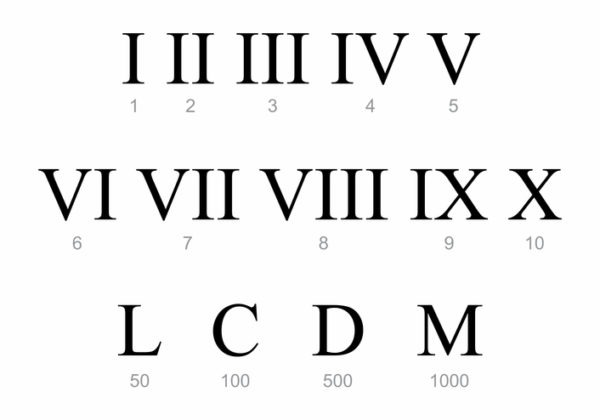

In [ ]:
# Diccionario con los valores de cada número romano
table = {
    'I': 1,
    'V': 5,
    'X': 10,
    'L': 50,
    'C': 100,
    'D': 500,
    'M': 1000
}

def roman_to_int(str):
    result = 0
    for i in range(len(str) - 1):
        if table[str[i]] < table[str[i + 1]]:
            result -= table[str[i]]
        else:
            result += table[str[i]]
    return result + table[str[-1]]

# --- Ejemplo de uso ---
numero_romano = "XIVDCI"  # Representa el 14 (10 - 1 + 5)
resultado = roman_to_int(numero_romano)

print(f"El número romano {numero_romano} en entero es: {resultado}")

El número romano XIVDCI en entero es: 605


# EJERCICIOS

## **A**

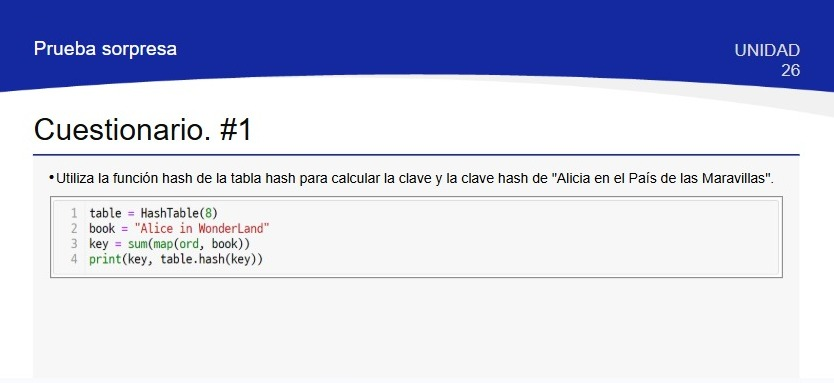

In [ ]:
#Definir Capacidad
capacidad = 8
#Libro a tratar
book = "Alice in WonderLand"
#Aplicar lógica de llave
key = sum(map(ord, book))
valor_hash = key % capacidad
print(f"Clave (key): {key}")
print(f"Clave hash: {valor_hash}")



Clave (key): 1763
Clave hash: 3


In [ ]:
class HashTable:
  def __init__(self, size):
    self.size = size
    self.table = {}
    for i in range (size):
      self.table[i] = []

  def hash(self, key):
    return key % self.size

 #Definir Capacidad
table = HashTable(8)
#Libro a tratar
book = "Alice in Wonderland"
#Aplicar lógica de llave
key = sum(map(ord, book))
print(f"Clave (key): {key}")
print(f"Clave hash: {valor_hash}")

Clave (key): 1795
Clave hash: 3


### respuesta 1

In [ ]:
class HashTable:
    def __init__(self, size):
        self.size = size
        self.table = {}
        for i in range(size):
            self.table[i] = []

    def hash(self, key):
        return key % self.size

# Configuración con los parámetros indicados
table = HashTable(8)
book = "Alice in Wonderland"
key = sum(map(ord, book))

# Cálculo de la clave hash usando el método de la clase
hash_value = table.hash(key)

print(f"Clave (key): {key}")
print(f"Clave hash: {hash_value}")

Clave (key): 1795
Clave hash: 3


In [ ]:
# Definimos la capacidad y la cadena tal como pide el ejercicio
capacidad = 8
book = "Alice in WonderLand"

# 1. Calculamos la clave sumando los valores ASCII de cada letra
key = sum(map(ord, book))

# 2. Calculamos la posición o clave hash usando el módulo con la capacidad (8)
hash_value = key % capacidad

print(f"Clave (key): {key}")
print(f"Clave hash (índice): {hash_value}")

Clave (key): 1763
Clave hash (índice): 3


## **B**

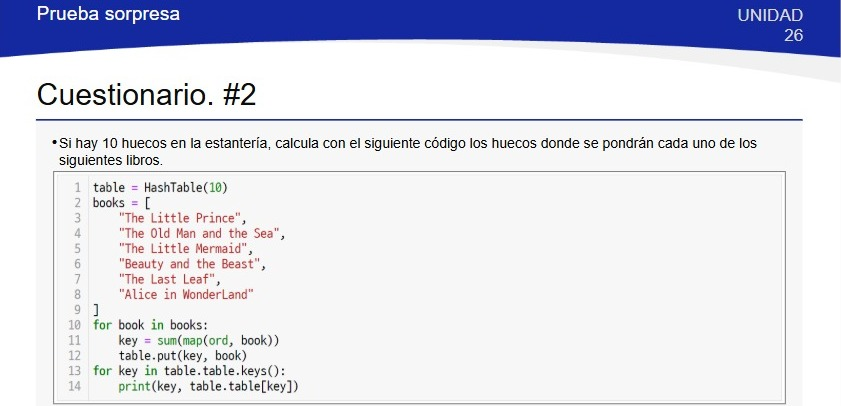

### respuesta 2

In [ ]:
class HashTable:
    def __init__(self, size):
        self.size = size
        # Usamos un diccionario interno para almacenar las claves y sus valores
        self.table = {}

    def _hash(self, key):
        return key % self.size

    def put(self, key, value):
        # Calculamos la posición usando el método hash
        indice = self._hash(key)
        # Guardamos el libro en la tabla
        self.table[key] = value


# --- Configuración del ejercicio ---
table = HashTable(10)

books = [
    "The Little Prince",
    "The Old Man and the Sea",
    "The Little Mermaid",
    "Beauty and the Beast",
    "The Last Leaf",
    "Alice in WonderLand"
]

# Insertamos cada libro calculando su clave (suma ASCII)
for book in books:
    key = sum(map(ord, book))
    table.put(key, book)

# Imprimimos los resultados tal como lo hace el bucle final de la imagen
for key in table.table.keys():
    print(key, table.table[key])

1584 The Little Prince
1929 The Old Man and the Sea
1678 The Little Mermaid
1837 Beauty and the Beast
1133 The Last Leaf
1763 Alice in WonderLand


In [ ]:
class HashTable:
    def __init__(self, size):
        self.size = size
        # Creamos una lista de tamaño 'size' inicializada en None para representar los estantes
        self.table = [None] * size

    def _hash(self, key):
        return key % self.size

    def put(self, key, value):
        # Calculamos la posición (estante) usando el método hash
        indice = self._hash(key)
        # Guardamos el libro en el estante correspondiente
        self.table[indice] = value


# --- Configuración del ejercicio ---
table = HashTable(10)

books = [
    "The Little Prince",
    "The Old Man and the Sea",
    "The Little Mermaid",
    "Beauty and the Beast",
    "The Last Leaf",
    "Alice in WonderLand"
]

# Insertamos cada libro calculando su clave (suma ASCII)
for book in books:
    key = sum(map(ord, book))
    table.put(key, book)

# Imprimimos todos los estantes (del 0 al size - 1), mostrando también los vacíos
for indice, book in enumerate(table.table):
    if book is not None:
        print(f"Estante {indice}: {book}")
    else:
        print(f"Estante {indice}: [Vacío]")

Estante 0: [Vacío]
Estante 1: [Vacío]
Estante 2: [Vacío]
Estante 3: Alice in WonderLand
Estante 4: The Little Prince
Estante 5: [Vacío]
Estante 6: [Vacío]
Estante 7: Beauty and the Beast
Estante 8: The Little Mermaid
Estante 9: The Old Man and the Sea
